In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import sunpy
import sunpy.map
import dkist 
import dask.array as da
import h5py
from astropy.time import Time
from astropy.io import ascii, fits
from astropy.wcs import WCS
from astropy.visualization import (ImageNormalize, 
                    SqrtStretch, AsinhStretch)
from astropy.convolution import Gaussian2DKernel, convolve
import astropy.units as u
from ndcube import NDCube
import pandas as pd 
import scipy.ndimage as ndi
from scipy.ndimage import distance_transform_edt

from skimage import io, filters, exposure, morphology, feature, measure
from skimage.morphology import remove_small_objects, skeletonize, binary_dilation, disk
from skimage.filters import frangi, meijering, sato, threshold_otsu, gaussian
from skimage.restoration import denoise_bilateral
from skimage import measure
from skimage.registration import phase_cross_correlation
from skimage.draw import line
from scipy.ndimage import shift as nd_shift
from scipy.optimize import minimize

from destretch import destretchSeq

import sunkit_image.trace as trace
from skan import Skeleton, summarize

from sun_blinker import ImageBlinker

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


In [2]:
Hbeta_test_image_0 = np.load("../../data/pid_1_123_aux/VBI_syn_raster/Hbeta_syn_raster.npy")
Gband_test_image_0 = np.load("../../data/pid_1_123_aux/VBI_syn_raster/Gband_syn_raster.npy")

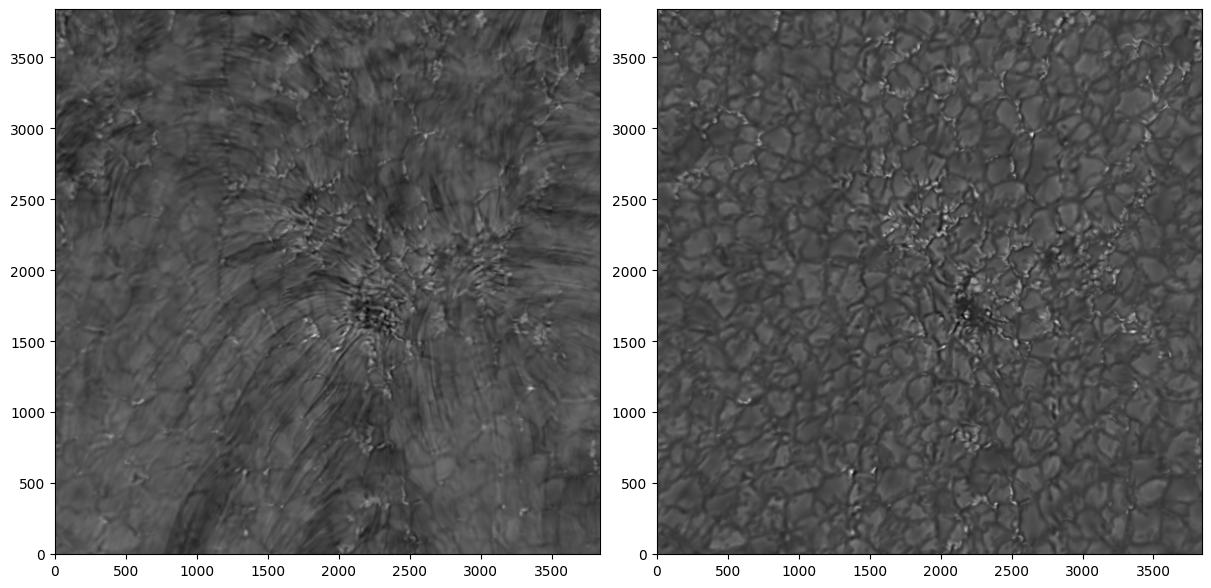

In [3]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
ax1.imshow(Hbeta_test_image_0, cmap="gray", origin="lower")
ax2.imshow(Gband_test_image_0, cmap="gray", origin="lower")

In [4]:
ImageBlinker(Hbeta_test_image_0, Gband_test_image_0, cmap1="gray", cmap2="gray",)

In [5]:
Hbeta_test_image_0_destretched, Gband_test_image_0_destretched = destretchSeq(
    np.array([Hbeta_test_image_0, Gband_test_image_0]),
    [128,96],
    rMean=3,
    globalTrack=[1500,1500,256]
)

In [6]:
ImageBlinker(Hbeta_test_image_0_destretched, Gband_test_image_0_destretched, cmap1="gray", cmap2="gray",)

In [7]:
def ridge_enhance(image, method="meijering", sigmas=range(1, 5), black_ridges=True):
    if method == "meijering":
        return meijering(image, sigmas=sigmas, black_ridges=black_ridges)
    if method == "sato":
        return sato(image, sigmas=sigmas, black_ridges=black_ridges)
    if method == "frangi":
        return frangi(image, sigmas=sigmas, black_ridges=black_ridges)
    raise ValueError(f"Unknown method: {method}")

In [8]:
def make_mask(enhanced, low_pct=70, high_pct=92, min_size=50, open_radius=2):
    lo, hi = np.nanpercentile(enhanced, (low_pct, high_pct))
    mask = filters.apply_hysteresis_threshold(enhanced, lo, hi)
    mask = remove_small_objects(mask, min_size=min_size)
    if open_radius > 0:
        mask = morphology.binary_opening(mask, morphology.disk(open_radius))
    return mask

In [9]:
Hbeta_ridge_enhanced = ridge_enhance(Hbeta_test_image_0_destretched, method="sato")
Gband_ridge_enhanced = ridge_enhance(Gband_test_image_0_destretched, method="sato")

In [10]:
Hbeta_mask = make_mask(Hbeta_ridge_enhanced, low_pct=70, high_pct=92, min_size=60, open_radius=2)

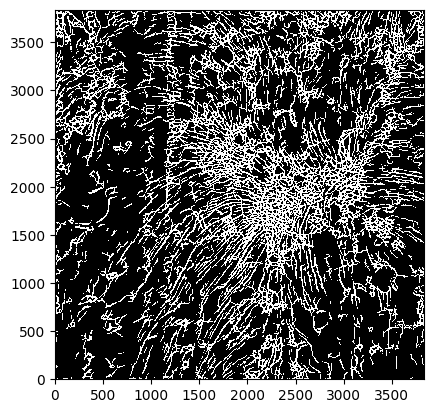

In [11]:
plt.imshow(Hbeta_mask, origin="lower", interpolation="none", cmap="gray")

In [12]:
def coalign_masks(mask_true, mask_bg, upsample_factor=1):
    """
    Coalign mask_bg to mask_true using phase cross-correlation.
    Precision is limited to 1 pixel (upsample_factor=1).

    Parameters
    ----------
    mask_true : 2D bool array
    mask_bg   : 2D bool array
    upsample_factor : int
        Kept at 1 for integer-pixel precision. Increase for sub-pixel
        (but shift will then be rounded to nearest integer anyway).

    Returns
    -------
    mask_bg_shifted : 2D bool array
        mask_bg shifted to align with mask_true.
    shift : (row_shift, col_shift) float tuple
        Detected shift in pixels (rows, cols). Positive = moved right/down.
    """
    shift_detected, _, _ = phase_cross_correlation(
        mask_true.astype(float),
        mask_bg.astype(float),
        upsample_factor=upsample_factor,
    )

    # Round to nearest integer pixel
    shift_int = np.round(shift_detected).astype(int)

    # Shift mask_bg — use order=0 (nearest neighbour) to keep it binary
    mask_bg_shifted = nd_shift(
        mask_bg.astype(float),
        shift=shift_int,
        order=0,          # nearest-neighbour: no interpolation artefacts
        mode='constant',
        cval=0,
    ).astype(bool)

    return mask_bg_shifted, tuple(shift_int)

In [13]:
Gband_mask = make_mask(Gband_ridge_enhanced, low_pct=70, high_pct=90, min_size=60, open_radius=2)
Gband_mask, _ = coalign_masks(Hbeta_mask, Gband_mask, upsample_factor=1)

ImageBlinker(Hbeta_mask, Gband_mask, cmap1="gray", cmap2="gray",
    norm1=ImageNormalize(vmin=0, vmax=1), norm2=ImageNormalize(vmin=0, vmax=1),)

In [14]:
def merge_target_func(params, img1, img2):
    a, b = params
    merge_image = img1 + a*img2 + b*img2*img2
    return np.nanstd(merge_image)

In [15]:
Hbeta_test_image_0_destretched_norm = ImageNormalize()(Hbeta_test_image_0_destretched)
Gband_test_image_0_destretched_norm = ImageNormalize()(Gband_test_image_0_destretched)

In [16]:
brightpoint_mask = make_mask(Gband_test_image_0_destretched_norm, low_pct=97, high_pct=98, min_size=30, open_radius=2)
brightpoint_mask = brightpoint_mask[1500:2000,2500:3000]

/cluster/home/zhuyin/sunpy_env/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:4842: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


In [17]:
poly_fit_param = np.polyfit(
              np.concatenate([Gband_test_image_0_destretched_norm[0:600,0:600].flatten(),
              Gband_test_image_0_destretched_norm[1500:2000,2500:3000][brightpoint_mask].flatten()]),
              np.concatenate([Hbeta_test_image_0_destretched_norm[0:600,0:600].flatten(),
              Hbeta_test_image_0_destretched_norm[1500:2000,2500:3000][brightpoint_mask].flatten()]),2)
poly_fit = np.poly1d(poly_fit_param)

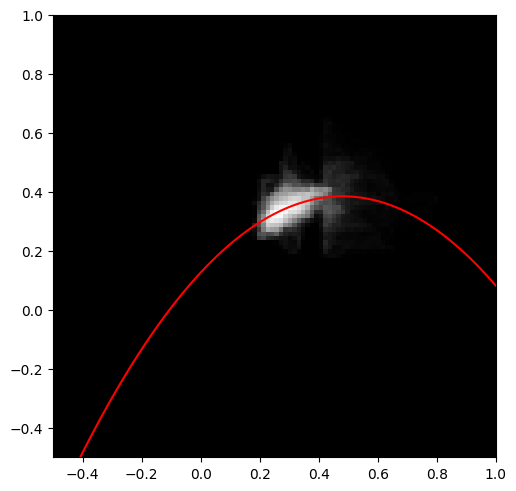

In [18]:
fig, ax = plt.subplots(layout="constrained")
_ = ax.hist2d(np.concatenate([Gband_test_image_0_destretched_norm[0:600,0:600].flatten(),
              Gband_test_image_0_destretched_norm[1500:2000,2500:3000][brightpoint_mask].flatten()]),
              np.concatenate([Hbeta_test_image_0_destretched_norm[0:600,0:600].flatten(),
              Hbeta_test_image_0_destretched_norm[1500:2000,2500:3000][brightpoint_mask].flatten()]),
              bins=100, cmap="gray", range=[[-0.5,1],[-0.5,1]],norm=ImageNormalize(stretch=AsinhStretch(0.01)))
ax.plot(
    np.linspace(-0.5, 1, 100),
    poly_fit(np.linspace(-0.5, 1, 100)),
    color="red"
)
ax.set_aspect(1)

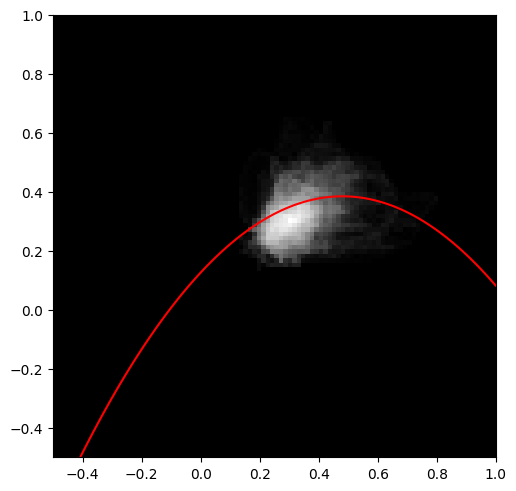

In [19]:
fig, ax = plt.subplots(layout="constrained")
_ = ax.hist2d(Gband_test_image_0_destretched_norm[1400:1900,2500:3000].flatten(),
              Hbeta_test_image_0_destretched_norm[1400:1900,2500:3000].flatten(), 
              bins=100, cmap="gray", range=[[-0.5,1],[-0.5,1]],norm=ImageNormalize(stretch=AsinhStretch(0.01)))
ax.plot(
    np.linspace(-0.5, 1, 100),
    poly_fit(np.linspace(-0.5, 1, 100)),
    color="red"
)
ax.set_aspect(1)

In [20]:
print(poly_fit_param)

[-1.12017683  1.07604335  0.1263749 ]


In [21]:
print(np.nanmean(Hbeta_test_image_0_destretched_norm[0:600,0:600]), np.nanmean(Gband_test_image_0_destretched_norm[0:600,0:600]))

0.34254323363204675 0.2902721786952836


In [22]:
merge_result = minimize(merge_target_func, x0=[-1.5, 0], args=(Hbeta_test_image_0_destretched_norm, Gband_test_image_0_destretched_norm),
        bounds=[(-5, 5), (-5, 5)])

In [23]:
merge_result.x

array([-0.66335877,  0.56074045])

In [24]:
Hbeta_Gband_merge_test_image_0 = Hbeta_test_image_0_destretched_norm + \
    merge_result.x[0]*Gband_test_image_0_destretched_norm + \
    merge_result.x[1]*Gband_test_image_0_destretched_norm**2

In [25]:
Hbeta_Gband_merge_test_image_0 = Hbeta_test_image_0_destretched_norm - \
    poly_fit(Gband_test_image_0_destretched_norm)

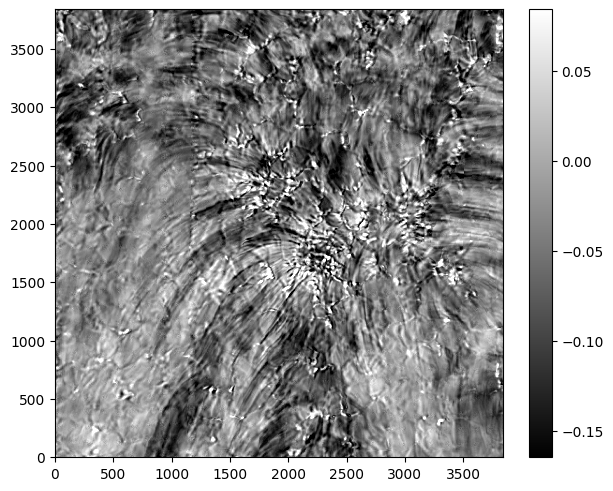

In [26]:
fig, ax = plt.subplots(layout="constrained")
im = ax.imshow(Hbeta_Gband_merge_test_image_0, origin="lower", interpolation="none", cmap="gray",
        vmin=np.nanpercentile(Hbeta_Gband_merge_test_image_0, 1), 
        vmax=np.nanpercentile(Hbeta_Gband_merge_test_image_0, 99))
fig.colorbar(im,ax=ax)
# ax.contour(Hbeta_Gband_merge_test_image_0, levels=[0.05], colors="red")

In [27]:
merge_enhanced = ridge_enhance(Hbeta_Gband_merge_test_image_0, method="sato",
        sigmas=range(2,8), black_ridges=True)
merge_mask = make_mask(merge_enhanced, low_pct=70, high_pct=90, min_size=60, open_radius=2)

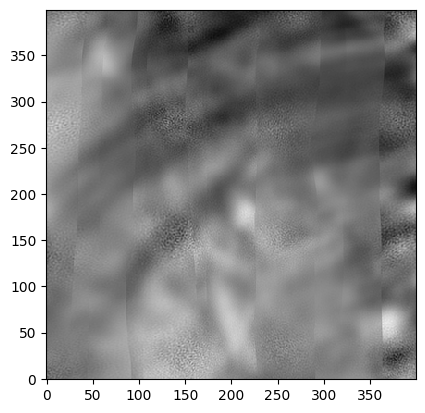

In [28]:
plt.imshow(Hbeta_Gband_merge_test_image_0[2500-200:2500+200, 1000-200:1000+200], origin="lower", interpolation="none", cmap="gray",
        vmin=np.nanpercentile(Hbeta_Gband_merge_test_image_0, 1), 
        vmax=np.nanpercentile(Hbeta_Gband_merge_test_image_0, 99))

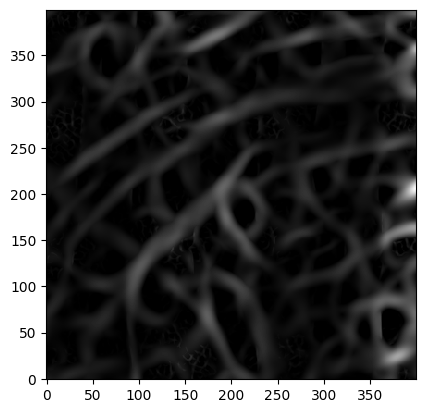

In [29]:
plt.imshow(merge_enhanced[2500-200:2500+200, 1000-200:1000+200], origin="lower", interpolation="none", cmap="gray",)

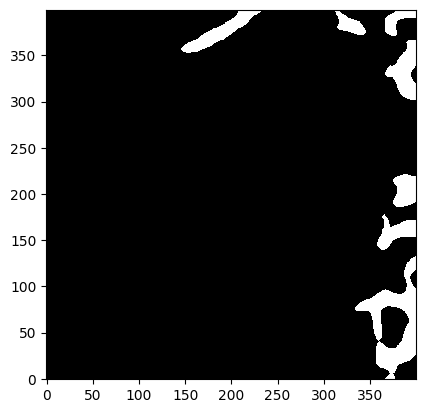

In [30]:
plt.imshow(merge_mask[2500-200:2500+200, 1000-200:1000+200], origin="lower", interpolation="none", cmap="gray",)

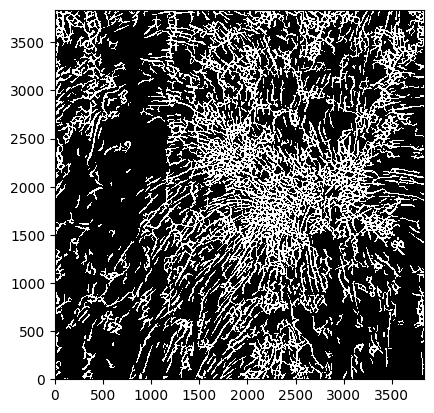

In [31]:
plt.imshow(merge_mask, origin="lower", interpolation="none", cmap="gray",)

In [32]:
ImageBlinker(merge_mask, Gband_mask, cmap1="gray", cmap2="gray",
norm1=ImageNormalize(vmin=0, vmax=1), norm2=ImageNormalize(vmin=0, vmax=1),)

In [36]:
def _find_junction_pixels(skel):
    """Pixels with 3 or more neighbours in the skeleton (8-connectivity)."""
    from scipy.ndimage import convolve
    kernel   = np.ones((3, 3), dtype=int)
    neighbor_count = convolve(skel.astype(int), kernel, mode='constant', cval=0)
    # A junction pixel is a skeleton pixel with ≥3 neighbours (including itself → ≥4)
    return skel & (neighbor_count >= 4)

def _split_at_junctions(skel, junction_mask):
    """Remove junction pixels from skeleton, label remaining arc segments."""
    skel_cut = skel & ~junction_mask
    labeled  = measure.label(skel_cut, connectivity=2)
    return labeled

def _reattach_junctions(skel_keep, junction_mask, labeled_arcs,
                         kept_arc_ids, dilation_radius=1):
    """
    Re-attach junction pixels that are within dilation_radius of any kept arc.
    Using the same dilation_radius as the BG overlap test ensures that
    junctions consumed by the dilated BG mask are still recovered.
    """
    kept_arcs_mask  = np.isin(labeled_arcs, list(kept_arc_ids))
    kept_dilated    = binary_dilation(kept_arcs_mask, disk(dilation_radius))
    junction_reattach = junction_mask & kept_dilated
    return skel_keep | junction_reattach

def filter_mask_by_background(mask_true, mask_bg,
                               dilation_radius=2,
                               min_overlap_fraction=0.5,
                               min_overlap_length=20):
    """
    Remove regions from mask_true that correspond to background skeleton
    components. Closed loops are first split at junction pixels into
    individual arc segments for finer-grained filtering. Junction pixels
    are re-attached if at least one neighbouring arc is kept.

    Parameters
    ----------
    mask_true : 2D bool array
    mask_bg   : 2D bool array
    dilation_radius : int
        Tolerance for skeleton misalignment.
    min_overlap_fraction : float in [0, 1]
        Fraction of arc pixels overlapping dilated BG skeleton to trigger removal.
    min_overlap_length : int
        Number of overlapping skeleton pixels to trigger removal.
        Both thresholds must be exceeded for removal.

    Returns
    -------
    mask_filtered : 2D bool array
    debug : dict
    """
    # --- Step 1: skeletonize ---
    skel_true = skeletonize(mask_true)
    skel_bg   = skeletonize(mask_bg)

    # --- Step 2: find and cut at junction pixels ---
    junction_mask = _find_junction_pixels(skel_true)
    labeled_arcs  = _split_at_junctions(skel_true, junction_mask)
    n_arcs        = labeled_arcs.max()

    # --- Step 3: dilate BG skeleton for overlap tolerance ---
    bg_dilated = binary_dilation(skel_bg, disk(dilation_radius))

    # --- Step 4: filter each arc segment ---
    skel_keep   = np.zeros_like(skel_true)
    skel_remove = np.zeros_like(skel_true)
    kept_arc_ids    = set()
    removed_arc_ids = set()

    for arc_id in range(1, n_arcs + 1):
        arc           = labeled_arcs == arc_id
        arc_pixels    = arc.sum()
        if arc_pixels == 0:
            continue

        overlap_pixels   = (arc & bg_dilated).sum()
        overlap_fraction = overlap_pixels / arc_pixels
        overlap_length   = overlap_pixels

        if (overlap_fraction > min_overlap_fraction and
                overlap_length   > min_overlap_length):
            skel_remove |= arc
            removed_arc_ids.add(arc_id)
        else:
            skel_keep   |= arc
            kept_arc_ids.add(arc_id)

    # --- Step 5: re-attach junction pixels touching at least one kept arc ---
    skel_keep = _reattach_junctions(skel_keep, junction_mask,
                                     labeled_arcs, kept_arc_ids,
                                     dilation_radius=dilation_radius)

    # --- Step 6: reconstruct mask from filtered skeleton ---
    dist = distance_transform_edt(mask_true)

    def _reconstruct(skel):
        if not skel.any():
            return np.zeros(mask_true.shape, dtype=bool)
        coords = np.argwhere(skel)
        radii  = dist[skel]
        result = np.zeros(mask_true.shape, dtype=bool)
        for radius in np.unique(np.round(radii).astype(int)):
            pts      = coords[np.round(radii).astype(int) == radius]
            pts_mask = np.zeros(mask_true.shape, dtype=bool)
            pts_mask[pts[:, 0], pts[:, 1]] = True
            result  |= binary_dilation(pts_mask, disk(radius))
        return result & mask_true

    region_keep   = _reconstruct(skel_keep)
    region_remove = _reconstruct(skel_remove)

    junction_preserved = region_remove & region_keep
    mask_filtered      = (region_keep | junction_preserved) & mask_true

    debug = dict(
        skel_true          = skel_true,
        skel_bg            = skel_bg,
        junction_mask      = junction_mask,
        labeled_arcs       = labeled_arcs,
        skel_kept          = skel_keep,
        skel_removed       = skel_remove,
        region_kept        = region_keep,
        region_removed     = region_remove,
        junction_preserved = junction_preserved,
        n_arcs             = n_arcs,
        n_kept             = len(kept_arc_ids),
        n_removed          = len(removed_arc_ids),
    )

    return mask_filtered, debug

In [61]:
Hbeta_mask_reconstructed, debug = filter_mask_by_background(merge_mask, Gband_mask,
                                                  dilation_radius=5, min_overlap_fraction=0.3,
                                                  min_overlap_length=5)

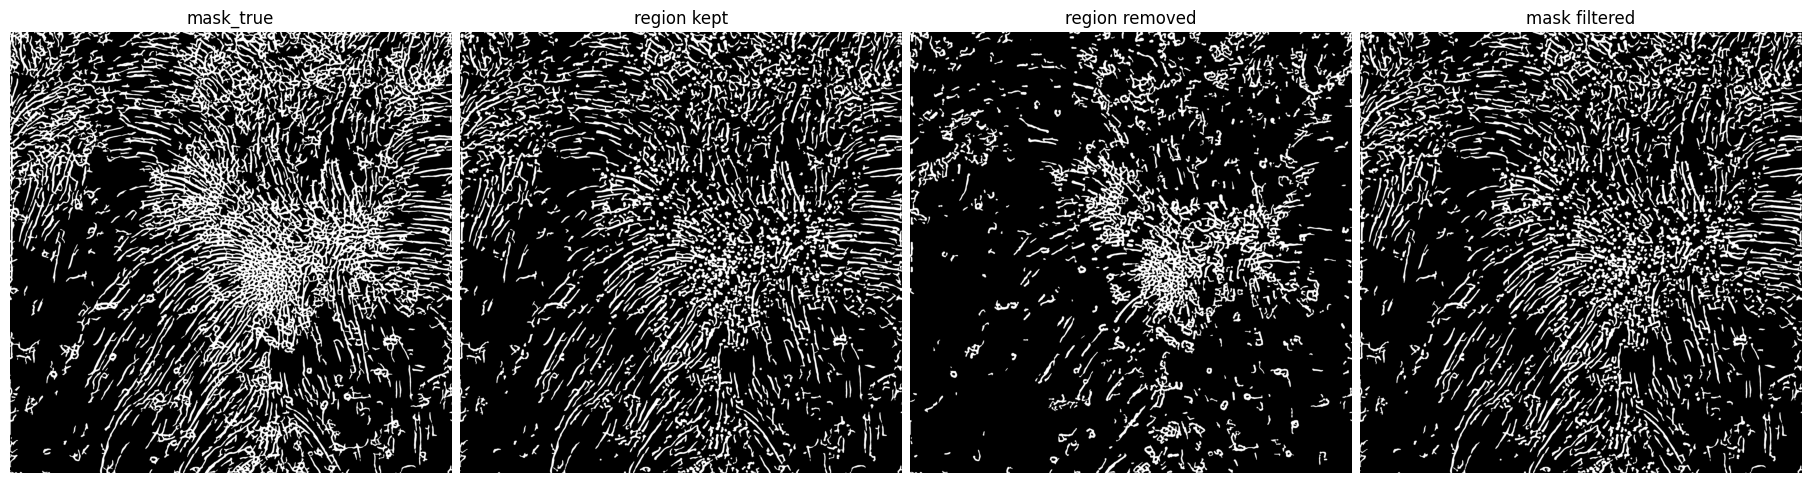

In [62]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5), constrained_layout=True)
axes[0].imshow(merge_mask,cmap='gray',origin='lower'); axes[0].set_title('mask_true')
axes[1].imshow(debug['region_kept'],cmap='gray', origin='lower'); axes[1].set_title('region kept')
axes[2].imshow(debug['region_removed'],cmap='gray', origin='lower'); axes[2].set_title('region removed')
axes[3].imshow(Hbeta_mask_reconstructed,cmap='gray', origin='lower'); axes[3].set_title('mask filtered')
for ax in axes: ax.axis('off')

In [78]:
Hbeta_mask_reconstructed_remove_small = remove_small_objects(Hbeta_mask_reconstructed, min_size=1000)

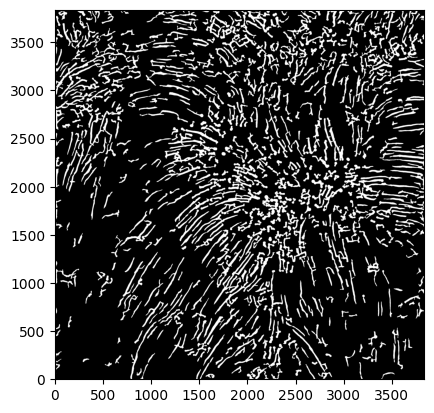

In [79]:
plt.imshow(Hbeta_mask_reconstructed_remove_small,cmap='gray', origin='lower')

In [44]:
def resolve_branch_columns(tab):
    branch_distance_col = "branch-distance" if "branch-distance" in tab.columns else "branch_distance"
    branch_type_col = "branch-type" if "branch-type" in tab.columns else "branch_type"
    if branch_distance_col not in tab.columns or branch_type_col not in tab.columns:
        raise KeyError(f"Could not find branch columns in summarize output: {tab.columns.tolist()}")
    return branch_distance_col, branch_type_col


def chord_length(coords):
    start, end = coords[0], coords[-1]
    return float(np.hypot(*(end - start)))


def curvature_profile(coords):
    if coords.shape[0] < 3:
        return np.array([], dtype=float)

    v1 = coords[1:-1] - coords[:-2]
    v2 = coords[2:] - coords[1:-1]
    l1 = np.hypot(v1[:, 0], v1[:, 1]) + 1e-12
    l2 = np.hypot(v2[:, 0], v2[:, 1]) + 1e-12
    dot = (v1 * v2).sum(axis=1) / (l1 * l2)
    dot = np.clip(dot, -1.0, 1.0)
    theta = np.arccos(dot)
    step = 0.5 * (l1 + l2)
    return theta / step


def prune_short_branches(skeleton, branch_min_length=40):
    sk = Skeleton(skeleton)
    tab = summarize(sk)
    branch_distance_col, branch_type_col = resolve_branch_columns(tab)
    out = skeleton.copy()

    for idx in tab.index:
        if tab.loc[idx, branch_type_col] >= 1 and tab.loc[idx, branch_distance_col] < branch_min_length:
            coords = sk.path_coordinates(idx)
            coords_to_remove = coords if coords.shape[0] <= 2 else coords[1:-1]
            if coords_to_remove.shape[0] == 0:
                continue

            rr, cc = np.round(coords_to_remove).T.astype(int)
            valid = (
                (rr >= 0)
                & (rr < out.shape[0])
                & (cc >= 0)
                & (cc < out.shape[1])
            )
            out[rr[valid], cc[valid]] = False

    out = remove_small_objects(out, min_size=2, connectivity=2)
    return out


def branch_measurements(
    skeleton,
    mask,
    pixel_scale=1.0,
    min_length_pix=10.0,
    tortuosity_max=1.2,
    rmin_pix=50.0,
    curvature_percentile=95.0,
):
    sk = Skeleton(skeleton)
    tab = summarize(sk, separator="_")
    dist = distance_transform_edt(mask)
    kappa_limit = 1.0 / (rmin_pix + 1e-12)

    rows = []
    for idx in tab.index:
        coords = sk.path_coordinates(idx)
        if coords.shape[0] < 2:
            continue

        rr, cc = np.round(coords).T.astype(int)
        valid = (
            (rr >= 0)
            & (rr < skeleton.shape[0])
            & (cc >= 0)
            & (cc < skeleton.shape[1])
        )
        rr, cc = rr[valid], cc[valid]
        if rr.size < 2:
            continue

        coords_valid = np.column_stack([rr, cc]).astype(float)
        seg_len_pix = np.hypot(np.diff(rr), np.diff(cc)).sum()
        if seg_len_pix < min_length_pix:
            continue

        chord_pix = chord_length(coords_valid)
        tort = seg_len_pix / (chord_pix + 1e-12)
        kappa = curvature_profile(coords_valid)
        kappa_q = 0.0 if kappa.size == 0 else float(np.nanpercentile(kappa, curvature_percentile))
        is_straight = (tort <= tortuosity_max) and (kappa_q <= kappa_limit)
        width_pix = 2.0 * np.nanmean(dist[rr, cc])

        rows.append(
            {
                "branch_id": int(idx),
                "length_pix": float(seg_len_pix),
                "length": float(seg_len_pix * pixel_scale),
                "width_pix": float(width_pix),
                "width": float(width_pix * pixel_scale),
                "tortuosity": float(tort),
                "curvature_q": float(kappa_q),
                "is_straight": bool(is_straight),
                "branch_type": int(tab.loc[idx, "branch_type"]),
                "coords": coords_valid,
            }
        )

    out = pd.DataFrame(rows)
    if out.empty:
        return out

    out = out.sort_values("length_pix", ascending=False).reset_index(drop=True)
    return out


def branch_table_to_mask(shape, branch_table, keep_column="is_straight"):
    out = np.zeros(shape, dtype=bool)
    if branch_table.empty:
        return out

    for _, row in branch_table.iterrows():
        if not bool(row[keep_column]):
            continue
        rr, cc = np.round(row["coords"]).T.astype(int)
        valid = (
            (rr >= 0)
            & (rr < shape[0])
            & (cc >= 0)
            & (cc < shape[1])
        )
        out[rr[valid], cc[valid]] = True

    return out


def endpoint_mask(skel):
    neigh = ndi.convolve(skel.astype(np.uint8), np.ones((3, 3), dtype=np.uint8), mode="constant", cval=0)
    return skel & (neigh == 2)


def endpoint_direction(skel, r, c):
    r0 = max(0, r - 1)
    r1 = min(skel.shape[0], r + 2)
    c0 = max(0, c - 1)
    c1 = min(skel.shape[1], c + 2)
    patch = skel[r0:r1, c0:c1]
    ys, xs = np.nonzero(patch)
    for yy, xx in zip(ys, xs):
        rr = yy + r0
        cc = xx + c0
        if rr == r and cc == c:
            continue
        vec = np.array([r - rr, c - cc], dtype=float)
        n = np.linalg.norm(vec)
        if n > 0:
            return vec / n
    return None


def link_skeleton_endpoints(skel, max_gap=10.0, angle_tol_deg=40.0, alpha=0.5):
    lbl, _ = ndi.label(skel, structure=np.ones((3, 3), dtype=np.uint8))
    ep = endpoint_mask(skel)
    pts = np.column_stack(np.nonzero(ep))
    if pts.shape[0] < 2:
        return skel.copy(), []

    dirs = []
    for r, c in pts:
        dirs.append(endpoint_direction(skel, int(r), int(c)))

    used = np.zeros(pts.shape[0], dtype=bool)
    tol = np.deg2rad(angle_tol_deg)
    links = []

    for i in range(pts.shape[0]):
        if used[i] or dirs[i] is None:
            continue

        best_j = -1
        best_score = np.inf
        p0 = pts[i].astype(float)
        d0 = dirs[i]

        for j in range(i + 1, pts.shape[0]):
            if used[j] or dirs[j] is None:
                continue
            if lbl[tuple(pts[i])] == lbl[tuple(pts[j])]:
                continue

            p1 = pts[j].astype(float)
            v = p1 - p0
            dist = np.linalg.norm(v)
            if dist <= 1e-12 or dist > max_gap:
                continue

            # scaled angle tolerance: loose at small gap, strict at large
            gap_frac = dist / max_gap
            effective_tol = tol * (1 + alpha * (1 - gap_frac))

            vhat = v / dist
            ang0 = np.arccos(np.clip(np.dot(d0, vhat), -1.0, 1.0))
            ang1 = np.arccos(np.clip(np.dot(dirs[j], -vhat), -1.0, 1.0))
            if ang0 > effective_tol or ang1 > effective_tol:
                continue

            score = dist + 0.5 * (ang0 + ang1)
            if score < best_score:
                best_score = score
                best_j = j

        if best_j >= 0:
            used[i] = True
            used[best_j] = True
            links.append((tuple(pts[i]), tuple(pts[best_j])))

    out = skel.copy()
    for (r0, c0), (r1, c1) in links:
        rr, cc = line(int(r0), int(c0), int(r1), int(c1))
        out[rr, cc] = True

    return out, links

In [102]:
def skel_stats(mask):
    skel = skeletonize(mask)
    skel_clean = prune_short_branches(skel, branch_min_length=35)
    # skel_clean = skel
    stats = branch_measurements(
        skel_clean,
        mask,
        pixel_scale=1.0,
        min_length_pix=20.0,
        tortuosity_max=1.2,
        rmin_pix=50.0,
        curvature_percentile=20.0,
    )
    straight_stats = stats[stats["is_straight"]].reset_index(drop=True) if not stats.empty else stats
    straight_skeleton = branch_table_to_mask(skel_clean.shape, stats, keep_column="is_straight")

    linked_skeleton, links = link_skeleton_endpoints(
        straight_skeleton,
        max_gap=50.0,
        angle_tol_deg=30.0,
        alpha=1
    )
    if len(links) == 0:
        bridge = morphology.binary_closing(straight_skeleton, morphology.disk(2))
        support = morphology.binary_dilation(mask, morphology.disk(1))
        grouped_skeleton = skeletonize(bridge & support)
    else:
        grouped_skeleton = skeletonize(linked_skeleton)
    
    linked_skeleton_2, links_2 = link_skeleton_endpoints(
        grouped_skeleton,
        max_gap=50.0,
        angle_tol_deg=30.0,
        alpha=1
    )

    if len(links_2) == 0:
        bridge = morphology.binary_closing(grouped_skeleton, morphology.disk(2))
        support = morphology.binary_dilation(mask, morphology.disk(1))
        grouped_skeleton = skeletonize(bridge & support)
    else:
        grouped_skeleton = skeletonize(linked_skeleton_2)
    
    grouped_skeleton = prune_short_branches(grouped_skeleton, branch_min_length=20)

    grouped_mask = morphology.binary_dilation(grouped_skeleton, morphology.disk(2))
    grouped_mask = grouped_mask & mask
    grouped_mask = morphology.remove_small_objects(grouped_mask, min_size=500)

    results = {
        "mask": mask,
        "skeleton": skel_clean,
        "straight_skeleton": straight_skeleton,
        "grouped_skeleton": grouped_skeleton,
        "grouped_mask": grouped_mask,
        "n_links": len(links),
        "stats_all": stats,
        "stats": straight_stats,
    }

    return results

In [103]:
Hbeta_mask_reconstructed_skel_res = skel_stats(merge_mask)

/scratch/tmp.65124222.zhuyin/ipykernel_1459689/1878291524.py:31: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  tab = summarize(sk)


/cluster/home/zhuyin/sunpy_env/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:4842: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


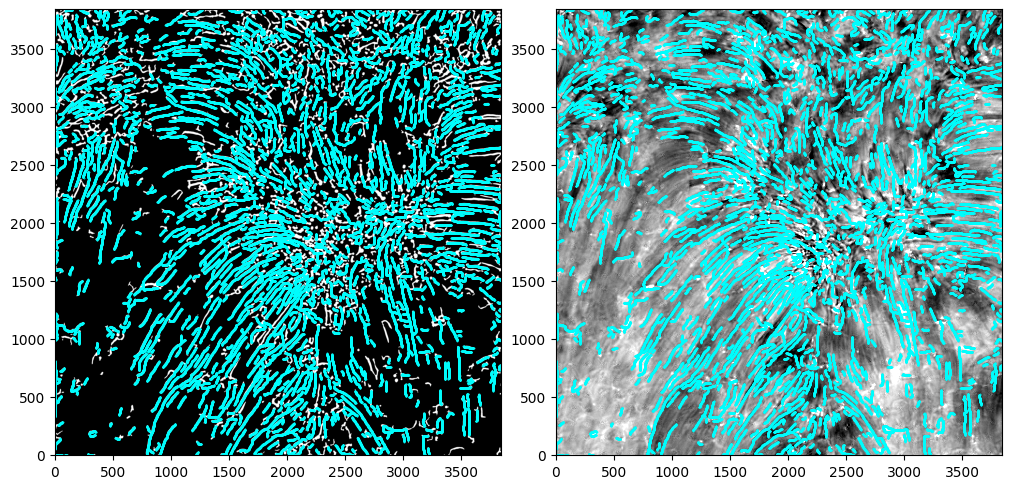

In [104]:
skel_ys, skel_xs = np.nonzero(Hbeta_mask_reconstructed_skel_res["grouped_skeleton"])
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(10,5), layout="constrained")
ax1.imshow(Hbeta_mask_reconstructed, cmap="gray", origin="lower")
ax2.imshow(Hbeta_Gband_merge_test_image_0, origin="lower", interpolation="none", cmap="gray",
        vmin=np.nanpercentile(Hbeta_Gband_merge_test_image_0, 1), 
        vmax=np.nanpercentile(Hbeta_Gband_merge_test_image_0, 99))

for ax_ in (ax1,ax2):
    ax_.scatter(skel_xs, skel_ys, s=0.2, c="cyan", alpha=0.8)

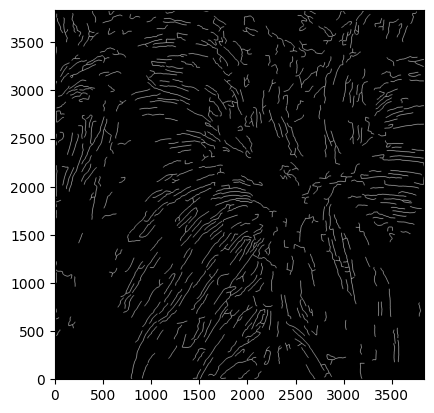

In [105]:
plt.imshow(Hbeta_mask_reconstructed_skel_res["grouped_mask"], cmap="gray", origin="lower")

In [109]:
Hbeta_mask_reconstructed_skel_res_to_save = dict(
    mask=Hbeta_mask_reconstructed_skel_res["mask"],
    skeleton=Hbeta_mask_reconstructed_skel_res["skeleton"],
    straight_skeleton=Hbeta_mask_reconstructed_skel_res["straight_skeleton"],
    grouped_skeleton=Hbeta_mask_reconstructed_skel_res["grouped_skeleton"],
    grouped_mask=Hbeta_mask_reconstructed_skel_res["grouped_mask"],
    n_links=Hbeta_mask_reconstructed_skel_res["n_links"],
    Hbeta_Gand_image=Hbeta_Gband_merge_test_image_0,
    Hbeta_image=Hbeta_test_image_0,
    Gband_image=Gband_test_image_0
)

In [110]:
np.savez("../../sav/fibril_tracing/Hbeta_mask_reconstructed_skel_res.npz", **Hbeta_mask_reconstructed_skel_res_to_save)

In [107]:
for keys in Hbeta_mask_reconstructed_skel_res.keys():
    print(keys, type(Hbeta_mask_reconstructed_skel_res[keys]))

mask <class 'numpy.ndarray'>
skeleton <class 'numpy.ndarray'>
straight_skeleton <class 'numpy.ndarray'>
grouped_skeleton <class 'numpy.ndarray'>
grouped_mask <class 'numpy.ndarray'>
n_links <class 'int'>
stats_all <class 'pandas.core.frame.DataFrame'>
stats <class 'pandas.core.frame.DataFrame'>


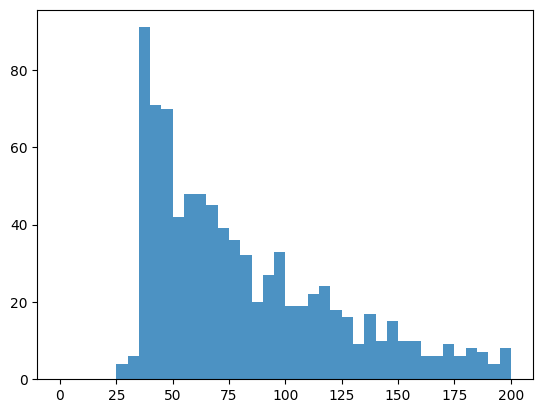

In [82]:
_ = plt.hist(Hbeta_mask_reconstructed_skel_res["stats"]["length_pix"], bins=40, color="tab:blue", alpha=0.8, range=[0, 200])